## Module 3: Computational Drug Discovery Project Final
By: Ashlee Hyun and Iliya Somov


## Project Goal:

We are working as a Quantitative Systems Pharmacologist at the UVA Manning Institute for Biotechnology. Our overall goal is to help develop a GLP1 agonist drug for weight loss, branded Cavalitide, that will compete with semaglutide (Ozempic or Wegovy). Our project is composed of three tasks:
* Task 1: Fit a receptor binding (pharmacodynamics) model for Cavalitide
* Task 2: Simulate the pharmacokinetics of Cavalitide treatment
* Task 3: Simulate a combined pharmacokinetics-pharmacodynamics (PKPD) model that predicts GLP1 receptor activity during treatment.
  

## Disease Background: 
Obesity is a chronic medical condition where excess body fat builds up in the body that can negatively impact health, quality of life, and longevity (World Health Organization, 2025).

- Prevalence and Incidence: Around 1.1 billion people in the world live with obesity, with roughly 16% of adults aged 18 and older affected as of 2024. At the same time, 170 million children/adolescents aged 5-19 were living with obesity, as well as 35 million children under age 5. Rapid obesity spikes occur in low- and middle-income countries, with rates of 32% in South-East Asia and Africa to 68% in the Americas (World Health Organization, 2025). Specifically in the U.S., 40.3% of adults have obesity, with 9.4% having severe obesity (Emmerich S. et al., 2024).

- Symptoms/Diagnosis: Obesity does not have a direct symptom, but carrying excess body fat creates physical strain and metabolic issues that often show in day to day living and in secondary health conditions. Some physical signs include: excess body fat accumulation, shortness of breath, joint and back pain, persistent fatigue, excessive sweating, and rashes/infections on the skin. Excess tissue around the neck can constrict airways during sleep, causing loud snoring or obstructive sleep apnea. Obesity is diagnosed through physical measurements like a Body Mass Index (BMI) of 30 or higher and high waist measurements (Mayo Clinic, n.d.). BMI can't distinguish muscle from fat, so waist circumference and waist-to-height/hip ratio are used to confirm excess body fat. Once excess body fat is confirmed, doctors evaluate whether it actually impairs health or not and classifies the obesity into two categories: preclinical obesity (excess body fat with regular organ function and normal daily mobility), and clinical obesity (heart failure, sleep apnea, metabolic syndrome) (The Lancet Diabetes & Endocrinology, 2025).

- Standard of care treatments (& reimbursement): obesity is regularly treated as a chronic, progressive disease that varies from individual to individual. Treatment includes behavioral & lifestyle therapy---targeting calorie deficit, increased physical activity, self-monitoring, and structured behavior changes. In addition, individuals with a BMI of over 30/27 kg/m^2 are offered pharmacotherapy, with medication changing overtime as well as nutritional/protein monitoring to prevent weight regain. In extreme cases, metabolic and bariatric surgery are recommended to patients with severe obesity or when lifestyle changes/pharmacotherapy do not result in sufficient health outcomes. Anti-obesity medications and bariatric surgery coverage varies by employer plan and state Medicaid policy, but traditional Part D plans have exclusions for drugs for weight loss (Baum C. et al., 2015).

- Disease progression & prognosis: Excess body fat (specifically visceral and ectopic fat) triggers chronic inflammation, insulin resistance, and hormonal shifts. Over time, the body adapts to a higher weight threshold, making weight gain progressive and weight loss difficut to sustain without continuous care. There are two categories: preclinical obesity (Stage 1) and clinical obesity (Stages 2-3). Through preclinical obesity does not affect organs or daily function, individuals carry a high risk of progressing to clinical obesity. Excess amounts of body fat causes tissue/organ dysfunction, physical limitations, or obesity-related complications/diseases. Without intervention, childhood/adolescnet obesity often lasts until adulthood. The peak BMI reached and the total number of years lived with excess weight show a direct relationship with long-term health risks (Rubino F. et al., 2025).
Untreated obesity can lead to type 2 diabeties, hypertension, dyslipidemia, cornorary artery disease, or heart failure, as well as metabolic dysfunction-associated steatotic liver disease which can progress to steatohepatitis. It also has an increased risk for at least 13 types of cancer, infertility, and pregnancy complications. Additionally, because biological appetite and metabolic adaptations continue after weight loss, stopping treatment commonly leads to weight regain.  Long-term prognosis is best when obesity is managed continuously like hypertension or diabetes (World Health Organization, 2025; Rubino F. et al., 2025).

- Biological mechanisms: Obesity develops through a complex neuroendocrine, metabolic, and inflammatory network that changes energy balance and defends higher body fat storage. In the brain, the hypothalamus uses hormonal signals to control appetite, but chronic overnutrition leads to leptin resistance, where the brain becomes unresponsive to cues from excess fat to be satisfied, and instead craves calorie-dense foods. At the same time, gut-brain signaling is altered by elevated hunger hormones like ghrelin and post-meal satiety hormones such as GLP-1, PYY, and amylin. As fat cells grow larger beyond their healthy capacity, they trigger chronic inflammation and spill excess lipids into vital organs like the liver and pancrease, driving insulin resistance. Finally, metabolic adaptation and genetic susceptibility lower resting energy and heighten hunger during weight loss, creating a biological push towards weight regain (Busebee B. et al., 2023).

**Motivation and project questions:** GLP-1 is one of the satiety hormones described above, and GLP-1 receptor agonists such as semaglutide are an effective obesity treatment: weekly semaglutide gave about 15% average weight loss after 68 weeks in the STEP 1 trial (Wilding J. et al., 2021). However, semaglutide is either a weekly injection (Ozempic) or a daily pill from which only about 1% of the dose is absorbed (the Wegovy pill). Our project asks three connected questions about a possible better pill, Cavalitide:
1. How tightly does Cavalitide bind the GLP1 receptor compared with semaglutide? (Task 1)
2. What daily pill dose gives a blood level of 0.5 nM? (Task 2)
3. What dose keeps about 90% of GLP1 receptors active, and what does that mean for competing with semaglutide? (Task 3)

## Task 1: Fit a receptor binding model for Cavalitide:

Your colleague in Lead Discovery has identified a small molecule, Cavalitide, and performed experiments testing its binding to the GLP1 receptor (below, and available as cavalitide_data.csv). You now aim to develop a pharmacodynamics model of how GLP1 and Cavalitide can each bind and activate the GLP1 receptor. 
a)	Adapt your previous codes for modeling semaglutide (fit_semaglutide.py, semaglutide_data.csv) to fit the Cavalitide binding data. 
b)	Show a plot of [Cavalitide] vs. Fraction active receptors (Fact) demonstrating a good fit.
c)	Provide the fitted value of Kd for Cavalitide. Interpret the Kd of Cavalitide versus that of semaglutide, commenting on advantages/disadvantages.

**Task 1 Code**

Fitted Kd2 (cavalitide) = 0.077 nM


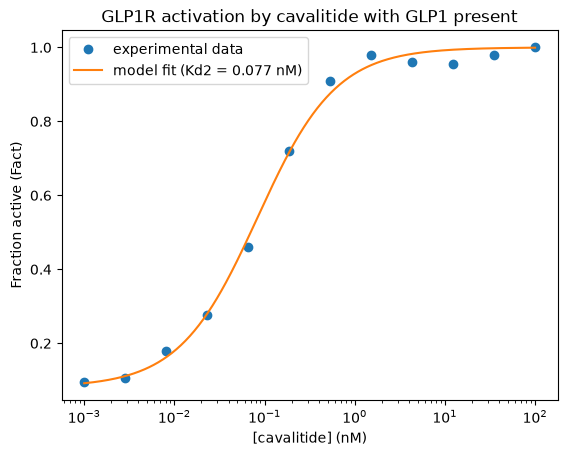

In [2]:
# Task 1: adapted from fit_semaglutide_GLP1R.py
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

def Fact(L1, L2, Kd1, Kd2):
    """Fractional receptor activation with two agonists L1 and L2"""
    return (Kd2*L1 + Kd1*L2) / (Kd1*Kd2 + Kd2*L1 + Kd1*L2)

# Parameters [nM]
Kd1 = 0.17    # L1, GLP1
L1 = 0.015    # [nM] GLP1 (fasting)

# Load the data
data = np.loadtxt("cavalitide_data.csv", delimiter=",", skiprows=1)
L2_loaded, Fact_loaded = data[:, 0], data[:, 1]

# Fit Kd2 (cavalitide) with curve_fit
popt, pcov = curve_fit(lambda L2, Kd2: Fact(L1, L2, Kd1, Kd2),
                       L2_loaded, Fact_loaded, p0=[0.1], bounds=(0, np.inf))
Kd2_fit = popt[0]
print(f"Fitted Kd2 (cavalitide) = {Kd2_fit:.3f} nM")

L2 = np.logspace(-3, 2, 500)  # [nM] cavalitide
plt.semilogx(L2_loaded, Fact_loaded, "o", label="experimental data")
plt.semilogx(L2, Fact(L1, L2, Kd1, Kd2_fit), label=f"model fit (Kd2 = {Kd2_fit:.3f} nM)")
plt.xlabel("[cavalitide] (nM)")
plt.ylabel("Fraction active (Fact)")
plt.title("GLP1R activation by cavalitide with GLP1 present")
plt.legend()
plt.show()

**b)** The model curve goes through the data points above it seems to be a good fit.

**c) Fitted Kd for Cavalitide = 0.077 nM** (semaglutide: 0.38 nM). Cavalitide's Kd is about 5 times smaller, so it binds the GLP1 receptor about 5 times more tightly and activates the same fraction of receptors at about 5 times lower concentration.
- **Advantages:** less drug is needed for the same effect, which matters for a pill because only about 1% of an oral dose is absorbed (less drug per pill, lower cost). It also binds more tightly than natural GLP1 (Kd = 0.17 nM).
- **Disadvantages:** receptors become fully activated at low concentrations, so it is easier to over-activate them (more side effects such as nausea), and small dosing errors have a bigger effect.

## Task 2: Simulate the pharmacokinetics of Cavalitide treatment

Your boss is really excited about the progress of your team in Task 1 on the development of Cavalitide. You’re now assigned to help design the Phase 1 clinical trial for the pill version of Cavalitide. 

1. Review the example code for modeling semaglutide pharmacokinetics (semaglutidePK.py). Run simulations for both Ozempic (subcutaneous injection once per week) and Wegovy (daily pill).  Replace the portion of the code using an explicit Euler’s method with use of the more powerful built-in function scipy.integrate.solve_ivp. Rerun the code to create plots that compare the predicted profiles of Ozempic and Wegovy.
2. Now, adapt semaglutidePK.py to additionally incorporate simulations of Cavalitide (daily pill), which has an increased absorption rate ka = 0.006 1/h. Plot how Cavalitide blood concentration changes over time.
3. Given the higher absorption rate, you hypothesize that you can further optimize the dosing strategy. Adjust one or two drug or dosing specific parameters until you achieve a steady state blood concentration close to 0.5 nM. Plot your result. What did you change about the dosing strategy and why?

**Task 2 Code**

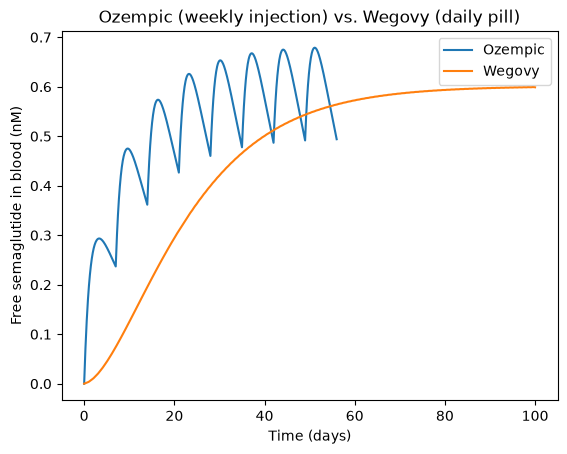

In [3]:
# Task 2.1: semaglutidePK.py with solve_ivp instead of Euler's method
from scipy.integrate import solve_ivp

# product-specific parameters (from semaglutidePK.py)
products = {
    'Ozempic': dict(Favailable=0.89, ka=0.029, D=2.0, interval=168, n_doses=8),   # weekly injection
    'Wegovy':  dict(Favailable=0.01, ka=0.0029, D=25, interval=24, n_doses=100),  # daily pill
}

# shared model parameters
ke = 0.0039     # 1/h, elimination rate
V = 10.8        # L
MW = 4113.6     # g/mol
Ffree = 0.01    # rest of semaglutide bound to albumin

def ODEfunc(t, y, ka):
    Asc, Cc = y
    dAsc = -ka*Asc            # Asc: depot amount (mg)
    dCc = ka*Asc/V - ke*Cc    # Cc: blood concentration (mg/L)
    return [dAsc, dCc]

def simulate(p):
    """Repeated dosing with solve_ivp; returns time (h) and blood concentration (nM)."""
    t_out, Cc_out = [], []
    y = [0.0, 0.0]
    for i in range(p['n_doses']):
        y[0] += p['Favailable']*p['D']        # absorbed fraction of dose enters the depot
        t0 = i * p['interval']
        sol = solve_ivp(ODEfunc, (t0, t0 + p['interval']), y, args=(p['ka'],),
                        t_eval=np.linspace(t0, t0 + p['interval'], 100))
        t_out.append(sol.t)
        Cc_out.append(sol.y[1])
        y = list(sol.y[:, -1])                # carry state into next interval
    t = np.concatenate(t_out)
    Cc_nM = np.concatenate(Cc_out) * 1e-3 / MW * 1e9   # mg/L -> nM
    return t, Cc_nM

for drug in ['Ozempic', 'Wegovy']:
    t, Cc = simulate(products[drug])
    plt.plot(t/24, Ffree*Cc, label=drug)
plt.xlabel("Time (days)")
plt.ylabel("Free semaglutide in blood (nM)")
plt.title("Ozempic (weekly injection) vs. Wegovy (daily pill)")
plt.legend()
plt.show()


**2.1)** Both drugs level off at about the same free blood concentration (about 0.6 nM), but the profiles are different. Ozempic (weekly injection, fast absorption) rises quickly and goes up and down every week. Wegovy (daily pill, slow absorption) rises slowly and smoothly and takes about 2 months to level off.

Steady-state concentration = 0.60 nM


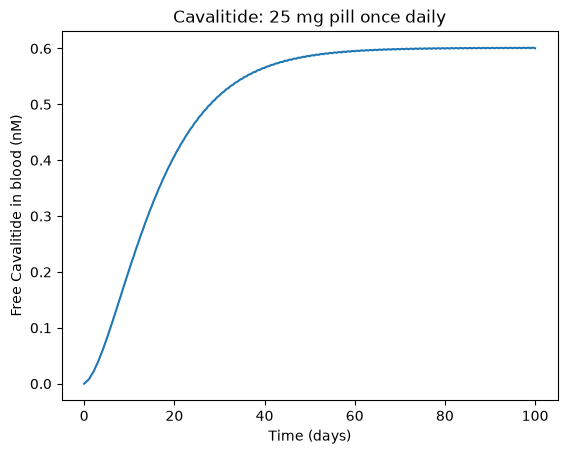

In [4]:
# Task 2.2: Cavalitide daily pill with faster absorption (other parameters same as Wegovy)
products['Cavalitide'] = dict(Favailable=0.01, ka=0.006, D=25, interval=24, n_doses=100)

t, Cc = simulate(products['Cavalitide'])
print(f"Steady-state concentration = {Ffree*Cc[-1]:.2f} nM")
plt.plot(t/24, Ffree*Cc)
plt.xlabel("Time (days)")
plt.ylabel("Free Cavalitide in blood (nM)")
plt.title("Cavalitide: 25 mg pill once daily")
plt.show()


**Task 2.2:** With the faster absorption, Cavalitide rises faster than the Wegovy pill (compared with the Task 2.1 plot) and levels off at the same free concentration, about 0.6 nM.

Steady-state concentration = 0.50 nM


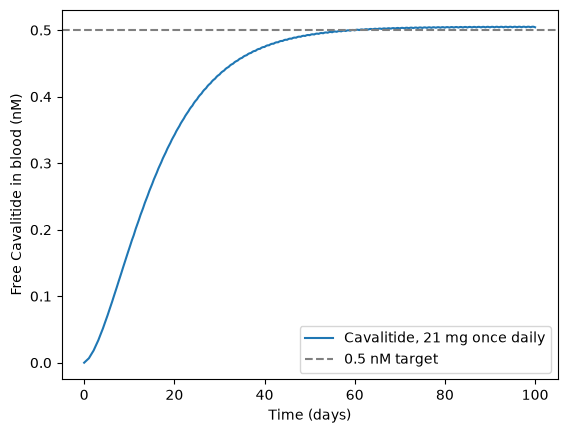

In [5]:
# Task 2.3: lower the dose from 25 mg to 21 mg per daily pill
products['Cavalitide']['D'] = 21

t, Cc = simulate(products['Cavalitide'])
print(f"Steady-state concentration = {Ffree*Cc[-1]:.2f} nM")
plt.plot(t/24, Ffree*Cc, label="Cavalitide, 21 mg once daily")
plt.axhline(0.5, ls="--", c="gray", label="0.5 nM target")
plt.xlabel("Time (days)")
plt.ylabel("Free Cavalitide in blood (nM)")
plt.legend()
plt.show()

**Task 2.3:** We lowered the dose from 25 mg to **21 mg per pill** and kept one pill per day. This gives a steady-state free blood concentration of about 0.50 nM (the free concentration plotted in semaglutidePK.py).

**Why:** At 25 mg, Cavalitide levels off at 0.6 nM, which is above the target. The steady-state level depends on how much drug is absorbed per day compared with how fast it is eliminated, so lowering the dose lowers the level proportionally (25 mg × 0.5/0.6 ≈ 21 mg). The faster absorption does not change the level; it only gets there sooner. We kept one pill per day because it is easy for patients, and the lower dose means less drug per pill.

## Task 3: Simulate a combined pharmacokinetics-pharmacokinetics (PKPD) model that predicts GLP1 receptor activity during treatment

The Phase 1 clinical trial was a success, and we achieved the desired 0.5 nM concentration of Cavalitide in your patients. Now it’s time to further customize the dosing for the Phase 2 clinical trial, where we are more interested in efficacy. We will need to combine the PK model (Task 2) and PD model (Task 1) to predict how the fraction of activated receptors changes over time.

1. Embed the ligand-receptor model of Cavalitide (from Task 1, but just using our optimized Kd) into our cavalitidePK.py model. Let’s call this combined model cavalitidePKPD.py. Predict how the fraction of active GLP1R receptors changes over the first 100 days of treatment. 
2. Further optimize your dosing strategy so that you achieve close to 90% active GLP1 receptors at steady state (around 100 days).  Which dosing parameters did we adjust? Provide an interpretation of the clinical benefits of this adjustment.


**Task 3 Code**

Steady-state Fact = 0.87


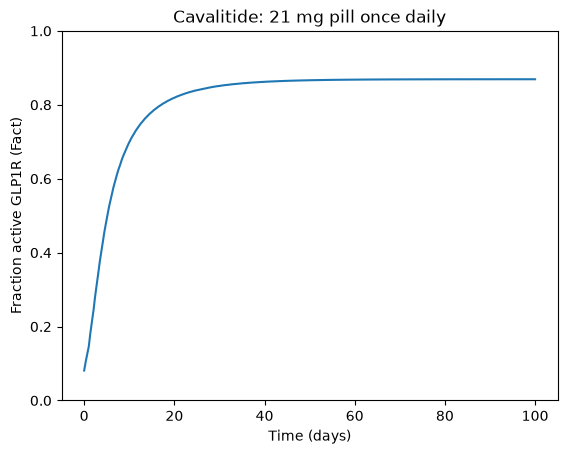

In [6]:
# Task 3.1: cavalitidePKPD.py = PK model (Task 2) + receptor binding model (Task 1)
Kd2 = 0.077   # [nM] cavalitide Kd from Task 1

t, Cc = simulate(products['Cavalitide'])      # 21 mg once daily (Task 2.3)
Fact_t = Fact(L1, Ffree*Cc, Kd1, Kd2)         # free Cavalitide -> fraction of active receptors
print(f"Steady-state Fact = {Fact_t[-1]:.2f}")
plt.plot(t/24, Fact_t)
plt.ylim(0, 1)
plt.xlabel("Time (days)")
plt.ylabel("Fraction active GLP1R (Fact)")
plt.title("Cavalitide: 21 mg pill once daily")
plt.show()


**Task 3.1:** Before treatment, GLP1 alone activates only about 8% of receptors. As Cavalitide builds up, the fraction of active receptors rises quickly over the first 2–3 weeks and levels off at about 87% at steady state.

Steady-state Fact = 0.90


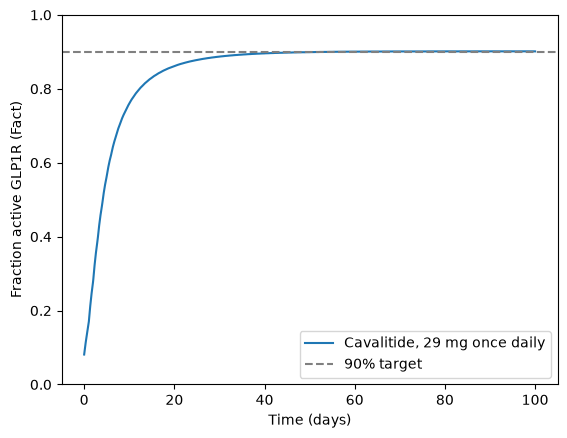

In [7]:
# Task 3.2: raise the dose to 29 mg per daily pill
products['Cavalitide']['D'] = 29

t, Cc = simulate(products['Cavalitide'])
Fact_t = Fact(L1, Ffree*Cc, Kd1, Kd2)
print(f"Steady-state Fact = {Fact_t[-1]:.2f}")
plt.plot(t/24, Fact_t, label="Cavalitide, 29 mg once daily")
plt.axhline(0.9, ls="--", c="gray", label="90% target")
plt.ylim(0, 1)
plt.xlabel("Time (days)")
plt.ylabel("Fraction active GLP1R (Fact)")
plt.legend()
plt.show()

**Task 3.2:** We increased the dose from 21 mg to **29 mg per pill** (still once daily, other parameters unchanged), which gives about **90% active GLP1 receptors** at steady state.

**Clinical benefits:** more active receptors should mean stronger appetite suppression and more weight loss, still with one pill a day. At 90%, the receptors are almost saturated, so the effect stays steady even if a patient's drug level varies a little. Going much above 90% would need a lot more drug for little extra benefit and more risk of side effects.

## Verification and Validation:

In [ ]:
# 1) Goodness of fit for the cavalitide fit (Task 1): R^2 = 1 - SSE/SST
SSE = np.sum((Fact_loaded - Fact(L1, L2_loaded, Kd1, Kd2_fit))**2)
SST = np.sum((Fact_loaded - np.mean(Fact_loaded))**2)
print(f"Cavalitide fit: R^2 = {1 - SSE/SST:.3f}")

# 2) Same fitting method on the semaglutide data -> compare with the published Kd (0.38 nM)
data_sema = np.loadtxt("semaglutide_data.csv", delimiter=",", skiprows=1)
popt_sema, pcov_sema = curve_fit(lambda L2, Kd2: Fact(L1, L2, Kd1, Kd2),
                                 data_sema[:, 0], data_sema[:, 1], p0=[0.1], bounds=(0, np.inf))
print(f"Semaglutide fit: Kd = {popt_sema[0]:.2f} nM (published: 0.38 nM)")

# 3) PK model half-life compared with the published semaglutide half-life (about 1 week)
print(f"Model half-life = ln(2)/ke = {np.log(2)/ke:.0f} h = {np.log(2)/ke/24:.1f} days")

- **Fit quality:** R² = 0.997, so the binding model explains almost all of the variation in the Cavalitide data.
- **Fitting method:** the same code gives Kd = 0.35 nM for the semaglutide data, close to the published 0.38 nM [1], so we trust our Cavalitide Kd.
- **PK model vs. published data:** the model half-life (7.4 days) and the time Ozempic takes to level off in our simulation (about 4–5 weeks, Task 2.1 plot) match the Ozempic label: a half-life of about 1 week and steady state after 4–5 weekly doses [3].
- **Numerical check:** solve_ivp reproduces the results of the class Euler code.
- **Sources of error:** the assumed Cavalitide properties, a single in vitro dataset and the simple models (see Limitations).

## Additional Analysis: Cavalitide vs. Semaglutide

Ozempic: steady-state Fact = 0.63
Wegovy: steady-state Fact = 0.62
Cavalitide: steady-state Fact = 0.90


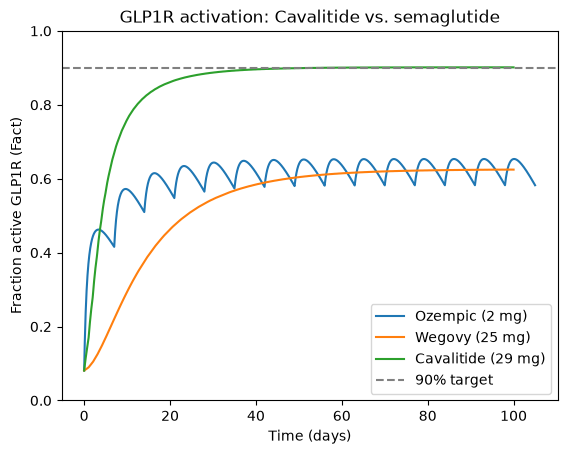

In [9]:
# GLP1R activation with Cavalitide vs. semaglutide, using the same PK and PD models
Kd_sema = 0.38                          # [nM] semaglutide (published value)
products['Ozempic']['n_doses'] = 15     # 15 weekly injections, so Ozempic also covers about 100 days

for drug, Kd in [('Ozempic', Kd_sema), ('Wegovy', Kd_sema), ('Cavalitide', Kd2)]:
    t, Cc = simulate(products[drug])
    Fact_drug = Fact(L1, Ffree*Cc, Kd1, Kd)          # fraction of active receptors over time
    last_week = t >= t[-1] - 7*24                     # last 7 days = steady state
    print(f"{drug}: steady-state Fact = {np.mean(Fact_drug[last_week]):.2f}")
    plt.plot(t/24, Fact_drug, label=f"{drug} ({products[drug]['D']:g} mg)")
plt.axhline(0.9, ls="--", c="gray", label="90% target")
plt.ylim(0, 1)
plt.xlabel("Time (days)")
plt.ylabel("Fraction active GLP1R (Fact)")
plt.title("GLP1R activation: Cavalitide vs. semaglutide")
plt.legend(loc="lower right")
plt.show()

With the same PK and PD models and semaglutide's published Kd of 0.38 nM (10), Ozempic (2 mg weekly) and the Wegovy pill (25 mg daily) keep only about 62–63% of GLP1 receptors active at steady state, while the 29 mg Cavalitide pill keeps about 90% active and levels off sooner than the Wegovy pill. Ozempic goes up and down every week, while both pills give a steady level. This supports our conclusion that Cavalitide could give a stronger effect than semaglutide at a similar dose.

## Conclusions:


Our results suggest Cavalitide could compete well with semaglutide, especially with the Wegovy pill:
- **Stronger binding (Task 1):** Cavalitide's Kd (0.077 nM) is about 5 times smaller than semaglutide's (0.38 nM), so the same blood level activates more GLP1 receptors.
- **Faster absorption (Task 2):** Ozempic and the Wegovy pill both level off at about 0.6 nM in the blood, but the Wegovy pill takes about 2 months to get there. Cavalitide's faster absorption gets it to steady state sooner. Faster absorption does not raise the steady-state level; the dose does.
- **Strong receptor activation (Task 3):** Because Cavalitide binds so tightly, 21 mg per day (0.5 nM) already activates about 87% of receptors, and 29 mg per day reaches about 90%. Most of this activation is reached within the first 3 weeks.
- **Compared with the competitors:** Compared with the Wegovy pill, Cavalitide is the same kind of daily pill with a similar amount of drug (29 vs. 25 mg), but it binds more tightly and starts working sooner. Compared with Ozempic, it avoids injections, but it has to be taken every day instead of once a week.

Overall, Cavalitide looks promising as a better oral alternative to semaglutide. The main open questions are whether the stronger receptor activation actually leads to more weight loss, and whether it causes more side effects such as nausea. These need to be tested in the Phase 2 trial.

**Recommendation:** We recommend moving Cavalitide into the Phase 2 trial as a once-daily pill, starting at 21 mg (0.5 nM, about 87% active receptors) and increasing to 29 mg (about 90% active receptors) over several weeks, while tracking weight loss and GI side effects.

**Ethical implications:**
- **Patient safety:** Our doses are model predictions, not proof. Phase 2 participants need informed consent, a low starting dose and close monitoring for side effects such as nausea (Wilding J. et al., 2021).
- **Access and cost:** Weight-loss drugs are often not covered by insurance (for example, traditional Medicare Part D plans exclude them; Baum C. et al., 2015), so Cavalitide's price will decide who benefits. A pill may also help patients who avoid injections.
- **Fair trials:** Our model uses the same parameters for every patient, so the trial should include people of different body weights, ages, sexes and ethnic backgrounds to make sure the dose works for everyone.

## Limitations and Future Work:


**Limitations:**
- **Simple binding model:** We assume binding is at equilibrium and that every bound receptor is active. The model ignores receptors becoming less responsive after long activation (desensitization) and the signaling steps after binding.
- **Simple PK model:** One depot and one blood compartment with first-order kinetics (no peripheral compartment), and the same parameters for every patient. In real patients, how much of a pill is absorbed varies with food and water and from person to person.
- **GLP1 fixed at the fasting level:** In reality, GLP1 rises after every meal.
- **Assumed Cavalitide properties:** Only the absorption rate was given, so we assumed its bioavailability, elimination rate, volume, molecular weight and albumin binding are the same as semaglutide's. Since Cavalitide is described as a small molecule, its molecular weight is probably much smaller, which would change the mg doses we found.
- **Limited data:** The Kd comes from one in vitro experiment (12 data points at one GLP1 level), and none of our predictions were compared with patient data.
- **No link to outcomes:** Our model predicts receptor activation, not weight loss or side effects.

**Future work:**
- Measure Cavalitide's real properties (bioavailability, half-life, molecular weight, albumin binding) and fit the PK parameters to blood concentration data from the Phase 1 trial.
- Repeat the binding experiment (more replicates, different GLP1 levels) to get a more reliable Kd.
- Add differences between patients (body weight, absorption) to predict the range of responses and pick a dose that works for most patients.
- Simulate meals, missed doses, and starting at a low dose and increasing it over several weeks to reduce nausea (as is done for semaglutide).
- Connect receptor activation to appetite, weight loss and side effects, and compare our predictions with Phase 2 results for Cavalitide and semaglutide.

## AI Usage Statement:
We used Claude to help assist us in this notebook. We used it to help us create the transition for Euler's Method and also used it for syntax/functions that Python had avaliable for us. It was also used to help in formatting the graphs and in the validation code. Microsoft Copilot helped a bit with the background section for finding sources and checking information.

## GitHub Repository Link:
https://github.com/ashlee171/BME2315_Module3


## References:
1. World Health Organization. Obesity and overweight. Published December 8, 2025. Accessed November 17, 2026. https://www.who.int/news-room/fact-sheets/detail/obesity-and-overweight
2. Emmerich SD, Fryar CD, Stierman B, Ogden CL. Obesity and severe obesity prevalence in adults: United States, August 2021–August 2023. NCHS Data Brief, no 508. National Center for Health Statistics; 2024. https://www.cdc.gov/nchs/products/databriefs/db508.htm
3. Mayo Clinic Staff. Obesity: symptoms and causes. Mayo Clinic. Accessed November 17, 2026. https://www.mayoclinic.org/diseases-conditions/obesity/symptoms-causes/syc-20375742
4. The Lancet Diabetes & Endocrinology. Clinical obesity: text-only infographic. Published 2025. Accessed November 12, 2026. https://www.thelancet.com/pb-assets/Lancet/infographics/clinical-obesity/Clinical_Obesity_-_text-only-1736175269007.pdf
5. Baum C, Andino K, Wittbrodt E, Stewart S, Szymanski K, Turpin R. The challenges and opportunities associated with reimbursement for obesity pharmacotherapy in the USA. *Pharmacoeconomics*. 2015;33(7):643-653. doi:[10.1007/s40273-015-0264-0](https://doi.org/10.1007/s40273-015-0264-0)
6. Rubino F, Cummings DE, Eckel RH, et al. Definition and diagnostic criteria of clinical obesity. *Lancet Diabetes Endocrinol*. 2025;13(3):221-262. doi:[10.1016/S2213-8587(24)00316-4](https://doi.org/10.1016/S2213-8587(24)00316-4)
7. Busebee B, Ghusn W, Cifuentes L, Acosta A. Obesity: a review of pathophysiology and classification. *Mayo Clin Proc*. 2023;98(12):1842-1857. doi:[10.1016/j.mayocp.2023.05.026](https://doi.org/10.1016/j.mayocp.2023.05.026)
8. Wilding JPH, Batterham RL, Calanna S, et al. Once-weekly semaglutide in adults with overweight or obesity. *N Engl J Med*. 2021;384(11):989-1002. doi:[10.1056/NEJMoa2032183](https://doi.org/10.1056/NEJMoa2032183)
9. BME 2315 Module 3 course materials: lectures, November 10 class notes, and class code (fit_semaglutide_GLP1R.py, semaglutidePK.py, semaglutide_data.csv, cavalitide_data.csv). University of Virginia; 2026.
10. Lau J, Bloch P, Schäffer L, et al. Discovery of the once-weekly glucagon-like peptide-1 (GLP-1) analogue semaglutide. *J Med Chem*. 2015;58(18):7370-7380. doi:[10.1021/acs.jmedchem.5b00726](https://doi.org/10.1021/acs.jmedchem.5b00726)
11. Novo Nordisk. Ozempic (semaglutide) injection, for subcutaneous use: prescribing information. US Food and Drug Administration; revised October 2025. Accessed November 15, 2026. https://www.accessdata.fda.gov/drugsatfda_docs/label/2025/209637s035%2C209637s037lbl.pdf

## NOTES FROM YOUR TEAM: 
*This is where our team is taking notes and recording activity.*

Notes/communication and recording were taken in groupchat made at the start of the module.

## QUESTIONS FOR YOUR TA: 
*These are questions we have for our TA.*

No questions.